In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets,transforms
from torch.utils.data import random_split, DataLoader
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score



In [2]:
transform=transforms.ToTensor()
train_dataset=datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)
test_dataset=datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [3]:
train_subset,val_subset=random_split(
    train_dataset,
    [54000,6000],
    generator=torch.Generator().manual_seed(42)
)
train_loader=DataLoader(
    train_subset,
    batch_size=64,
    shuffle=True
)
val_loader=DataLoader(
    val_subset,
    batch_size=65,
    shuffle=False
)
test_loader=DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)
print("training images:",len(train_subset))
print("validation images:",len(val_subset))
print("test images:",len(test_dataset))


training images: 54000
validation images: 6000
test images: 10000


In [4]:
import torch
import torch.nn as nn

class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

print("FashionCNN class defined successfully!")

FashionCNN class defined successfully!


In [5]:
model=FashionCNN()
loss_fn=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.001)
print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [6]:
images,labels=next(iter(train_loader))
print("images shape:",images.shape)
print("labels shape:",labels.shape)

images shape: torch.Size([64, 1, 28, 28])
labels shape: torch.Size([64])


In [9]:
device=torch.device(
    "cuda"if torch.cuda.is_available() else"cpu"

)
model=model.to(device)
print("device:",device)

device: cpu


In [10]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, device):
    model.train()
    total_loss = 0.0
    total_images = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_images += batch_size

    average_loss = total_loss / total_images

    print("Device:", device)
    print("Training loss:", round(average_loss, 4))

    return average_loss


train_loss = train_one_epoch(
    model, train_loader, loss_fn, optimizer, device
)

Device: cpu
Training loss: 0.5388


In [11]:
model.eval()
correct=0
total=0
with torch.no_grad():
  for images,labels in test_loader:
    images=images.to(device)
    labels=labels.to(device)
    outputs=model(images)
    predicted=outputs.argmax(dim=1)
    assert predicted.size(0)==labels.size(0)
    correct+=(predicted==labels).sum().item()
    total+=labels.size(0)
accuracy=100.0*correct/total
print("total test images:",total)
print(f"correct predictions:{correct}")
print(f"test accuracy:{accuracy:.2f}%")

total test images: 10000
correct predictions:8548
test accuracy:85.48%


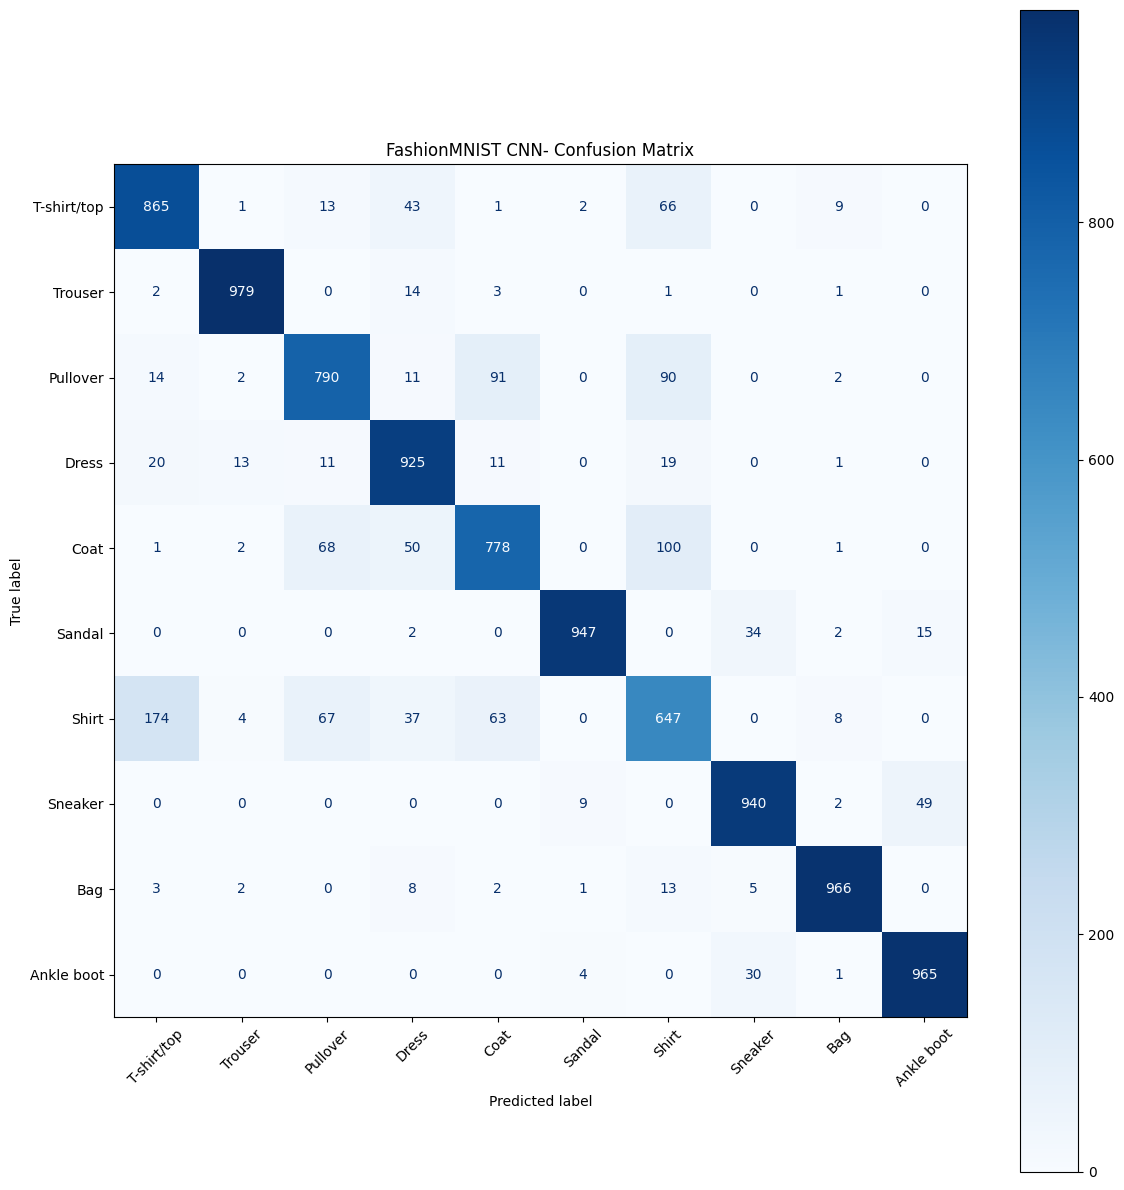

In [26]:
model.eval()
all_predictions=[]
all_labels=[]
with torch.no_grad():
  for images,labels in test_loader:
    images=images.to(device)
    outputs=model(images)
    predicted=outputs.argmax(dim=1)
    all_predictions.extend(predicted.cpu().tolist())
    all_labels.extend(labels.tolist())
class_names=test_loader.dataset.classes
cm=confusion_matrix(all_labels,all_predictions)
disp=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
fig,ax=plt.subplots(figsize=(12,12))
disp.plot(ax=ax,xticks_rotation=45,cmap="Blues")
plt.title("FashionMNIST CNN- Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "connfustion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

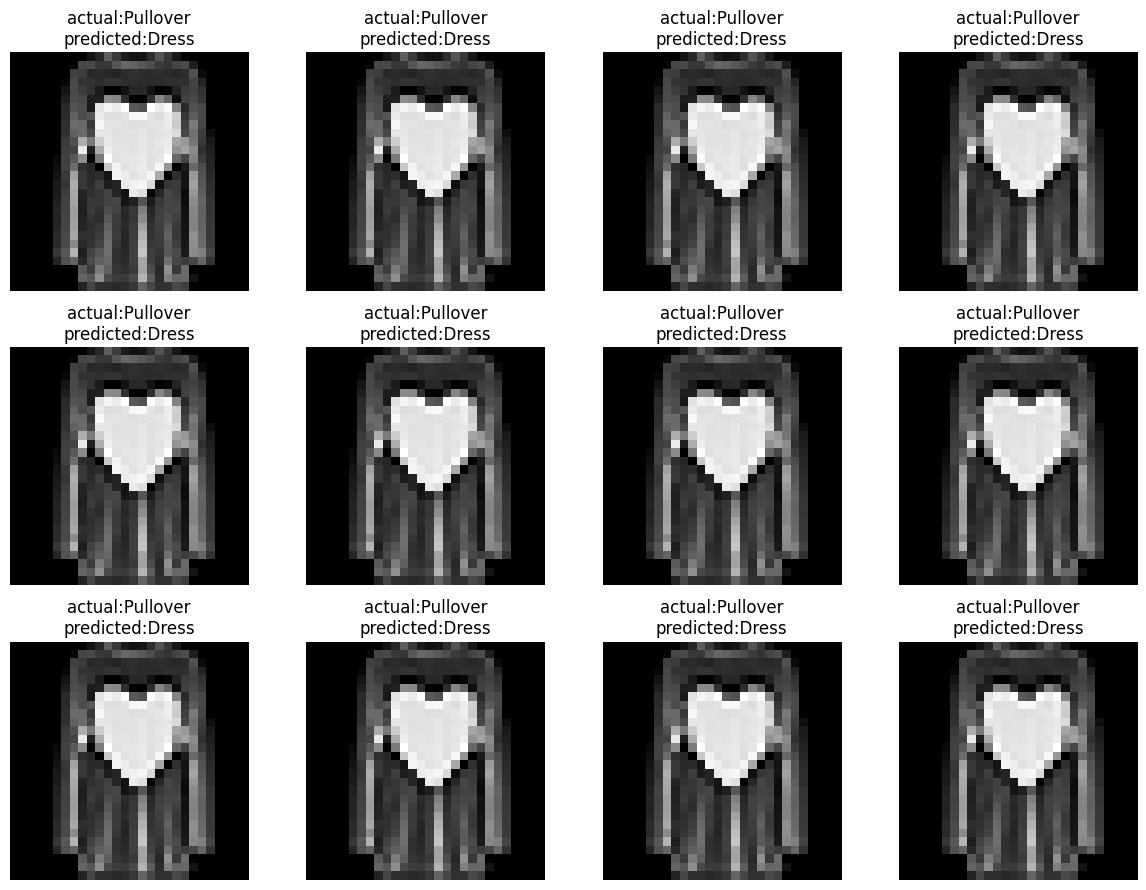

In [27]:
model.eval()
wrong_images=[]
wrong_actual=[]
wrong_predicted=[]
with torch.no_grad():
  for images.labels in test_loader:
    predictions=outputs.argmax(dim=1).cpu()
    wrong_indices=(predictions!=labels).nonzero().flatten()
    for idx in wrong_indices:
      wrong_images.append(images[idx].squeeze().cpu())
      wrong_actual.append(class_names[labels[idx].item()])
      wrong_predicted.append(class_names[predictions[idx].item()])
      if len(wrong_images)==12:
        break
    if len(wrong_images)==12:
      break
  fig,axes=plt.subplots(3,4,figsize=(12,9))
  for i,ax in enumerate(axes.flat):
    ax.imshow(wrong_images[i],cmap="gray")
    ax.set_title(
        f"actual:{wrong_actual[i]}\npredicted:{wrong_predicted[i]}"
    )
    ax.axis("off")
  plt.tight_layout()
  plt.savefig(
      "actual_vs_predicted.png",
      dpi=300,
      bbox_inches="tight"
  )
  plt.show()




In [14]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=3
))

              precision    recall  f1-score   support

 T-shirt/top      0.839     0.791     0.814      1000
     Trouser      0.987     0.972     0.979      1000
    Pullover      0.837     0.682     0.752      1000
       Dress      0.871     0.871     0.871      1000
        Coat      0.779     0.720     0.748      1000
      Sandal      0.980     0.942     0.961      1000
       Shirt      0.544     0.704     0.614      1000
     Sneaker      0.888     0.972     0.928      1000
         Bag      0.940     0.973     0.956      1000
  Ankle boot      0.969     0.921     0.945      1000

    accuracy                          0.855     10000
   macro avg      0.864     0.855     0.857     10000
weighted avg      0.864     0.855     0.857     10000



In [16]:
accuracy=accuracy_score(all_labels,all_predictions)
print(f"accuracy:{accuracy*100:.2f}%")
print("number of predictions:",len(all_predictions))
print("number of labels:",len(all_labels))

accuracy:85.48%
number of predictions: 10000
number of labels: 10000


In [18]:
baseline_accuracy=accuracy_score(
    all_labels,all_predictions)
print(f"baseline accurac:y:{baseline_accuracy*100:.2f}%")
train_loss=train_one_epoch(
    model,train_loader,loss_fn,optimizer,device
)

baseline accurac:y:85.48%
Device: cpu
Training loss: 0.345


In [20]:
model.eval()
correct=0
total=0
with torch.no_grad():
  for images,labels in test_loader:
    images=images.to(device)
    labels=labels.to(device)
    outputs=model(images)
    predictions=outputs.argmax(dim=1)
    correct+=(predictions==labels).sum().item()
    total+=labels.size(0)
new_accuracy=100*correct/total
print("correct:",correct)
print("total:",total)
print("accuracy:",round(100*correct/total,2),"%")


correct: 8802
total: 10000
accuracy: 88.02 %


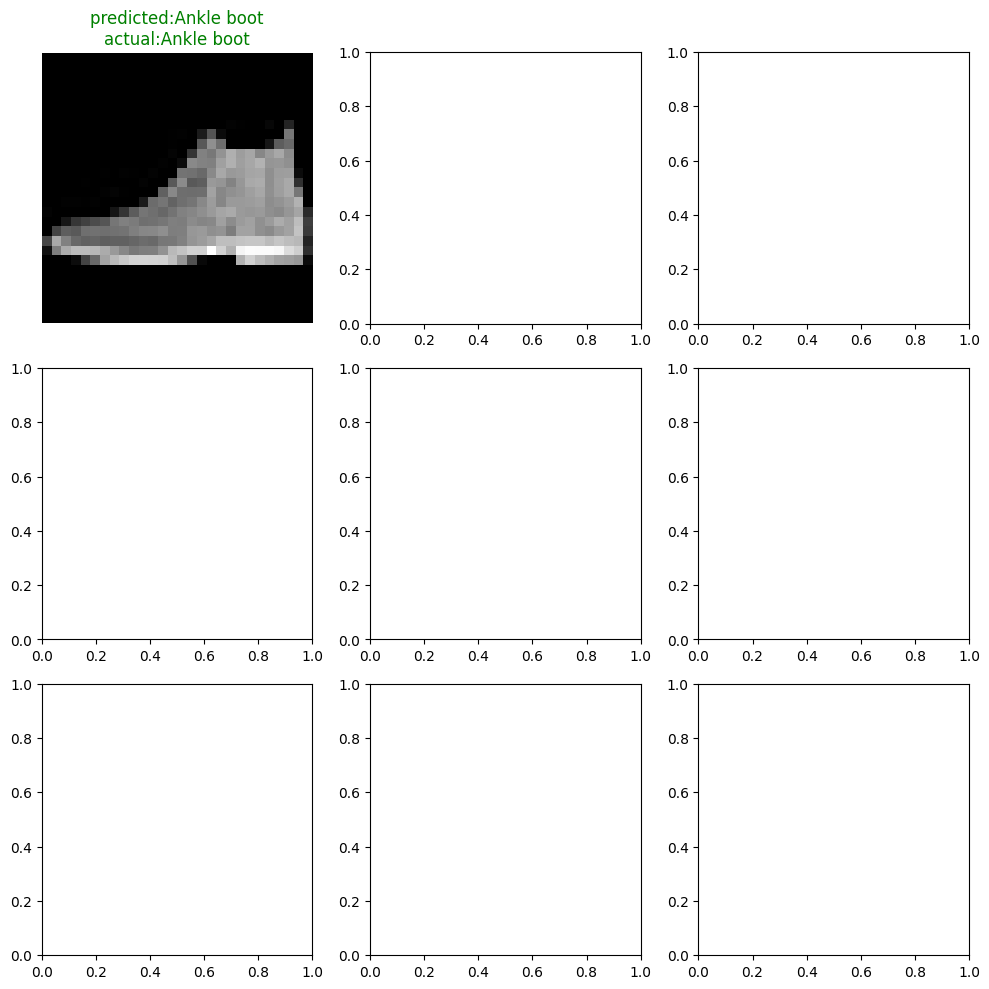

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [23]:
model.eval()
images,labels=next(iter(test_loader))
with torch.no_grad():
  outputs=model(images.to(device))
  predictions=outputs.argmax(dim=1).cpu()
class_names=test_loader.dataset.classes
fig,axes=plt.subplots(3,3,figsize=(10,10))
for i,ax in enumerate(axes.flat):
  ax.imshow(images[i].squeeze(),cmap="gray")
  actual=class_names[labels[i].item()]
  predicted=class_names[predictions[i].item()]
  color="green" if actual==predicted else "red"
  ax.set_title(
      f"predicted:{predicted}\nactual:{actual}",
      color=color
  )
  ax.axis("off")
  plt.tight_layout()
  plt.show()

In [25]:
torch.save(model.state_dict(),"fashion_cnn.pth")
print("model saved successfully")

model saved successfully
